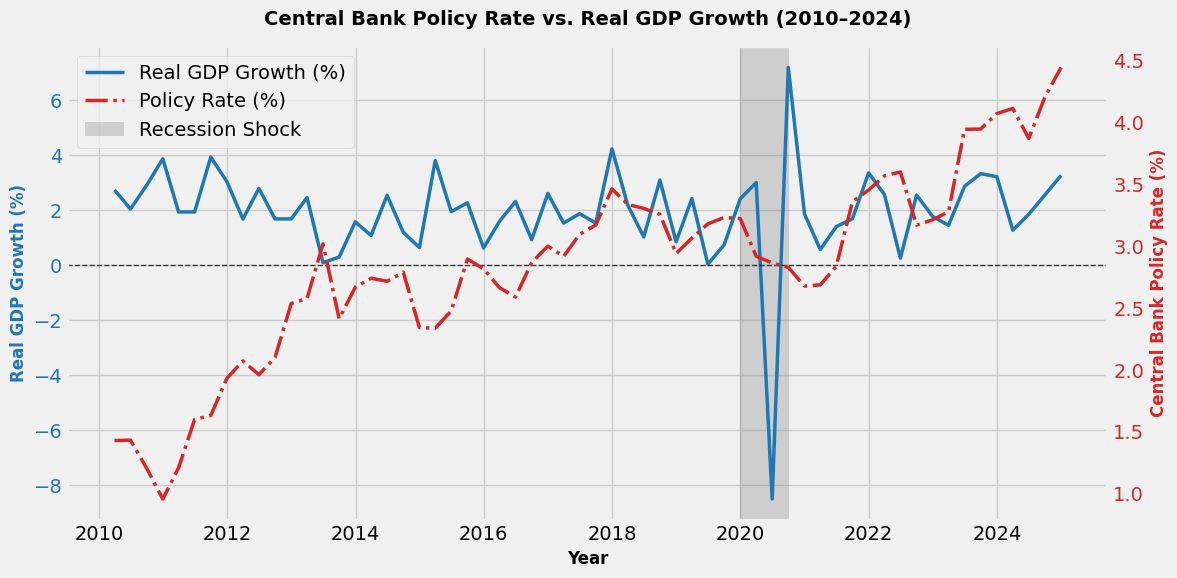

Macroeconomic dual-axis time-series chart rendered successfully!


In [67]:
# Worked Example: Dual-Axis Macroeconomic Time-Series Chart with Recession Shading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Set clean style
plt.style.use('fivethirtyeight')
np.random.seed(42)

# Generate quarterly date range for 15 years (2010 - 2024)
dates = pd.date_range(start='2010-01-01', periods=60, freq='QE')

# Generate synthetic macroeconomic series
gdp_growth = np.random.normal(loc=2.2, scale=1.1, size=60)
# Add COVID-19 shock in 2020 Q2
gdp_growth[41] = -8.5
gdp_growth[42] = 7.2

policy_rate = np.clip(np.cumsum(np.random.normal(loc=0.05, scale=0.25, size=60)) + 1.5, 0.25, 5.5)

macro_df = pd.DataFrame({
    'Date': dates,
    'GDP_Growth': gdp_growth,
    'Policy_Rate': policy_rate
}).set_index('Date')

# Create Figure and Axes
fig, ax1 = plt.subplots(figsize=(12, 6))

# Left Y-Axis: Real GDP Growth (%)
color1 = '#1f77b4'
ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Real GDP Growth (%)', color=color1, fontsize=12, fontweight='bold')
line1 = ax1.plot(macro_df.index, macro_df['GDP_Growth'], color=color1, linewidth=2.5, label='Real GDP Growth (%)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)

# Right Y-Axis: Policy Interest Rate (%)
ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Central Bank Policy Rate (%)', color=color2, fontsize=12, fontweight='bold')
line2 = ax2.plot(macro_df.index, macro_df['Policy_Rate'], color=color2, linewidth=2.5, linestyle='-.', label='Policy Rate (%)')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False) # Turn off grid for second axis to avoid visual clutter

# Shade Recession Period (e.g. 2020 COVID shock: 2020-01-01 to 2020-09-30)
ax1.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2020-09-30'), color='gray', alpha=0.3, label='Recession Shock')

# Format Title and Date Axis
plt.title('Central Bank Policy Rate vs. Real GDP Growth (2010–2024)', fontsize=14, fontweight='bold', pad=15)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines] + ['Recession Shock']
ax1.legend(lines + [plt.Rectangle((0,0),1,1,fc='gray',alpha=0.3)], labels, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

print("Macroeconomic dual-axis time-series chart rendered successfully!")

In [71]:
import inspect
print(inspect.getsource(plot_macro_policy_dual_axis))

def plot_macro_policy_dual_axis():

    np.random.seed(101)

    dates = pd.date_range(
        start="2005-01-31",
        periods=240,
        freq="ME"
    )

    n = len(dates)

    inflation = (
        2
        + 1.2 * np.sin(np.linspace(0, 12 * np.pi, n))
        + np.random.normal(0, 0.4, n)
    )

    unemployment = (
        5
        + 1.5 * np.cos(np.linspace(0, 10 * np.pi, n))
        + np.random.normal(0, 0.4, n)
    )

    crisis_2008 = (dates >= "2008-01-01") & (dates <= "2009-06-30")
    unemployment[crisis_2008] += 5
    inflation[crisis_2008] -= 0.8

    crisis_2020 = (dates >= "2020-01-01") & (dates <= "2020-12-31")
    unemployment[crisis_2020] += 6
    inflation[crisis_2020] -= 1

    df = pd.DataFrame({
        "Inflation": inflation,
        "Unemployment": unemployment
    }, index=dates)

    df.index.name = "Date"

    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax2 = ax1.twinx()

    line1 = ax1.plot(
        df.index,
        df["Inflation"],
        colo

In [72]:
# First 5 rows
print("First 5 Rows:")
print(macro_df.head())

# Last 5 rows
print("\nLast 5 Rows:")
print(macro_df.tail())

# Shape
print("\nDataset Shape:")
print(macro_df.shape)

# Missing values
print("\nMissing Values:")
print(macro_df.isnull().sum())

# Summary statistics
print("\nSummary Statistics:")
print(macro_df.describe())

First 5 Rows:
            GDP_Growth  Policy_Rate
Date                               
2010-03-31    2.746386     1.430206
2010-06-30    2.047909     1.433792
2010-09-30    2.912457     1.207208
2010-12-31    3.875333     0.958156
2011-03-31    1.942431     1.211288

Last 5 Rows:
            GDP_Growth  Policy_Rate
Date                               
2023-12-31    3.224408     4.071907
2024-03-31    1.276861     4.113229
2024-06-30    1.859866     3.871060
2024-09-30    2.564390     4.206765
2024-12-31    3.273100     4.444749

Dataset Shape:
(60, 2)

Missing Values:
GDP_Growth     0
Policy_Rate    0
dtype: int64

Summary Statistics:
       GDP_Growth  Policy_Rate
count   60.000000    60.000000
mean     1.933858     2.837812
std      1.821951     0.767546
min     -8.500000     0.958156
25%      1.375344     2.522256
50%      1.942440     2.882711
75%      2.758993     3.262908
max      7.200000     4.444749


In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch


def plot_macro_policy_dual_axis():

    np.random.seed(101)

    dates = pd.date_range(
        start="2005-01-31",
        periods=240,
        freq="ME"
    )

    n = len(dates)

    inflation = (
        2
        + 1.2 * np.sin(np.linspace(0, 12 * np.pi, n))
        + np.random.normal(0, 0.4, n)
    )

    unemployment = (
        5
        + 1.5 * np.cos(np.linspace(0, 10 * np.pi, n))
        + np.random.normal(0, 0.4, n)
    )

    crisis_2008 = (dates >= "2008-01-01") & (dates <= "2009-06-30")
    unemployment[crisis_2008] += 5
    inflation[crisis_2008] -= 0.8

    crisis_2020 = (dates >= "2020-01-01") & (dates <= "2020-12-31")
    unemployment[crisis_2020] += 6
    inflation[crisis_2020] -= 1

    df = pd.DataFrame({
        "Inflation": inflation,
        "Unemployment": unemployment
    }, index=dates)

    df.index.name = "Date"

    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax2 = ax1.twinx()

    line1 = ax1.plot(
        df.index,
        df["Inflation"],
        color="#1f77b4",
        linewidth=2,
        label="CPI Inflation (%)"
    )

    ax1.axhline(
        0,
        color="black",
        linestyle=":",
        linewidth=1
    )

    ax1.set_xlabel("Year")
    ax1.set_ylabel(
        "CPI Inflation Rate (%)",
        color="#1f77b4"
    )

    ax1.tick_params(
        axis="y",
        labelcolor="#1f77b4"
    )

    line2 = ax2.plot(
        df.index,
        df["Unemployment"],
        color="#ff7f0e",
        linestyle="--",
        linewidth=2,
        label="Unemployment Rate (%)"
    )

    ax2.set_ylabel(
        "Unemployment Rate (%)",
        color="#ff7f0e"
    )

    ax2.tick_params(
        axis="y",
        labelcolor="#ff7f0e"
    )

    ax2.grid(False)

    ax1.axvspan(
        pd.Timestamp("2008-01-01"),
        pd.Timestamp("2009-06-30"),
        color="lightgray",
        alpha=0.5
    )

    ax1.axvspan(
        pd.Timestamp("2020-01-01"),
        pd.Timestamp("2020-12-31"),
        color="mistyrose",
        alpha=0.6
    )

    ax1.xaxis.set_major_locator(mdates.YearLocator(3))
    ax1.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

    crisis

Inspection notice: name 'crisis' is not defined


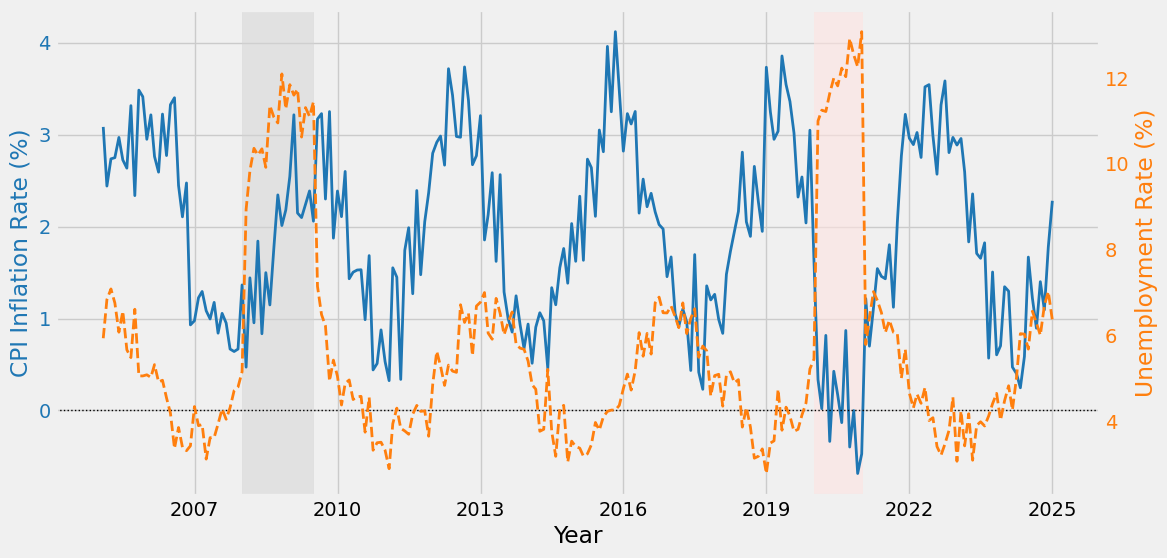

In [74]:
# ==============================================================================
# Inspection Cell: Dual-Axis Macro Policy Graphic & Summary Inspection
# ==============================================================================
try:
    macro_panel = plot_macro_policy_dual_axis()

    print("--- 1. Simulated Macro Panel (First 5 Months) ---")
    display(macro_panel.head())

    print("\n--- 2. Crisis Period Macro Summaries ---")
    crisis_2008 = macro_panel.loc['2008-01-01':'2009-06-30']
    print(f"2008 Financial Crisis — Max Unemployment: {crisis_2008['Unemployment'].max():.1f}%, Min Inflation: {crisis_2008['Inflation'].min():.1f}%")

    crisis_2020 = macro_panel.loc['2020-01-01':'2020-12-31']
    print(f"2020 Pandemic Shock — Max Unemployment: {crisis_2020['Unemployment'].max():.1f}%, Average Inflation: {crisis_2020['Inflation'].mean():.1f}%")

    print(f"\nTotal observations: {len(macro_panel)} monthly periods")
    print(f"Time span: {macro_panel.index.min().strftime('%Y-%m')} to {macro_panel.index.max().strftime('%Y-%m')}")
except Exception as e:
    print(f"Inspection notice: {e}")


[ERROR] Execution failed: name 'crisis' is not defined


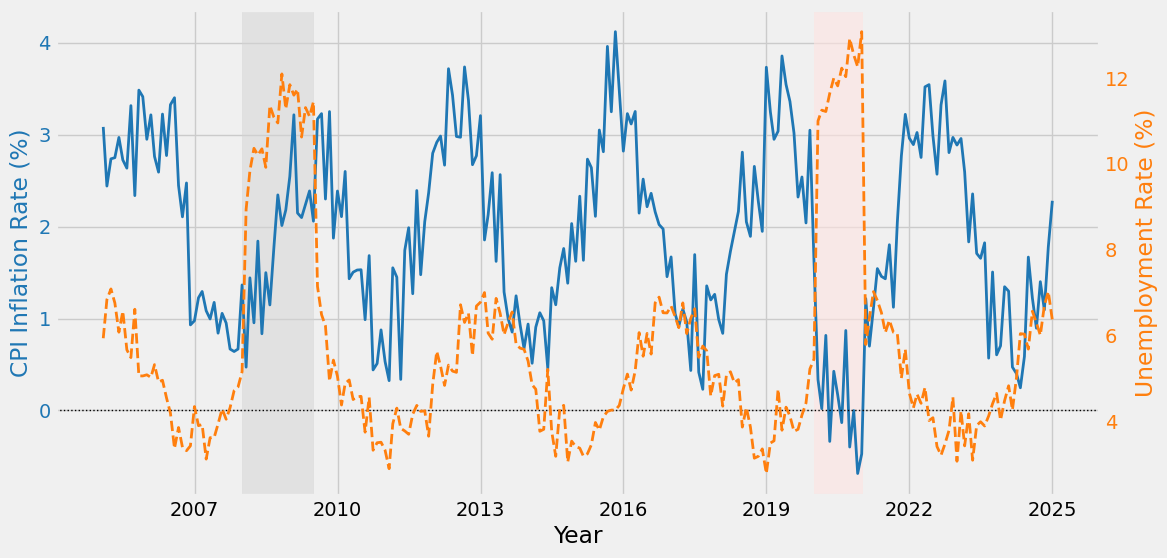

In [75]:
# Test cell for Exercise 1
# Run this cell to verify your implementation!
try:
    res_df = plot_macro_policy_dual_axis()

    # 1. Verify Return Type and Columns
    assert isinstance(res_df, pd.DataFrame), "Function must return a Pandas DataFrame."
    assert 'Inflation' in res_df.columns, "DataFrame must contain 'Inflation' column."
    assert 'Unemployment' in res_df.columns, "DataFrame must contain 'Unemployment' column."

    # 2. Verify DatetimeIndex & Length
    assert isinstance(res_df.index, pd.DatetimeIndex), "DataFrame index must be a DatetimeIndex."
    assert len(res_df) == 240, f"Expected 240 monthly observations, got {len(res_df)}."
    assert res_df.index[0].year == 2005, "Date range should begin in 2005."
    assert res_df.index[-1].year == 2024, "Date range should end in 2024."

    # 3. Verify Realistic Macro Bounds
    assert (res_df['Unemployment'] >= 0.0).all(), "Unemployment rate cannot be negative."
    assert res_df['Unemployment'].max() > 10.0, "Expected crisis spikes in unemployment to exceed 10%."

    print("[SUCCESS] Part 1 tests passed successfully!")
except Exception as e:
    print(f"[ERROR] Execution failed: {e}")

1. Code Logic & Tufte Graphical Design:
To improve the data-ink ratio, I removed unnecessary chart elements such as the top and right borders and used only light grid lines. I also added direct data labels so the values can be read easily without extra visual clutter. FuncFormatter automatically formats axis values as percentages, which makes the figure cleaner and more readable.
2. Ethics & Visual Scale Truncation:
Truncating the y-axis can make small differences look much larger than they really are. This can mislead readers and policymakers when interpreting economic data. For example, a small increase in inflation or GDP growth might appear very large if the chart does not start from an honest baseline.
3. AI Collaboration & Publication Standards Audit:
The AI included dpi=300 and bbox_inches='tight' to create a publication-quality figure suitable for reports and academic work. Vector formats such as PDF and SVG maintain quality when scaled, while raster formats such as PNG and JPG can lose sharpness when enlarged. High-quality exports are important for professional publications and policy reports.

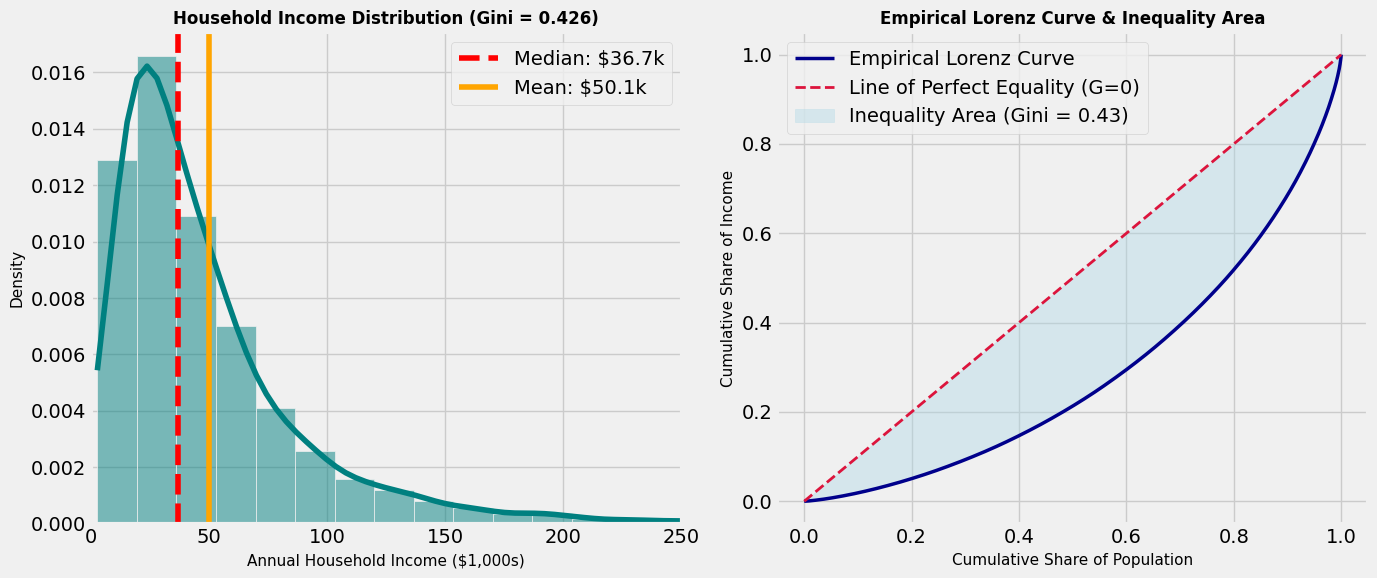

Calculated Gini Coefficient: 0.4265


In [46]:
# Worked Example: Household Income Distribution, KDE Fit & Empirical Lorenz Curve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# Generate synthetic right-skewed household income data (Lognormal distribution)
n_households = 5000
income = np.random.lognormal(mean=10.5, sigma=0.8, size=n_households) # Median ~ $40,000

# Function to calculate Gini coefficient
def calculate_gini(array):
    sorted_arr = np.sort(array)
    n = len(sorted_arr)
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * sorted_arr)) / (n * np.sum(sorted_arr))

gini_index = calculate_gini(income)

# Set up dual subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Income Distribution with KDE
sns.histplot(income / 1000, kde=True, ax=ax1, color='teal', bins=50, stat='density')
ax1.set_xlim(0, 250) # Limit x-axis for readability
ax1.set_title(f'Household Income Distribution (Gini = {gini_index:.3f})', fontsize=12, fontweight='bold')
ax1.set_xlabel('Annual Household Income ($1,000s)', fontsize=11)
ax1.set_ylabel('Density', fontsize=11)
ax1.axvline(np.median(income)/1000, color='red', linestyle='--', label=f'Median: ${np.median(income)/1000:.1f}k')
ax1.axvline(np.mean(income)/1000, color='orange', linestyle='-', label=f'Mean: ${np.mean(income)/1000:.1f}k')
ax1.legend()

# Subplot 2: Empirical Lorenz Curve
sorted_income = np.sort(income)
cum_income = np.cumsum(sorted_income) / np.sum(sorted_income)
cum_pop = np.linspace(0, 1, n_households)

ax2.plot(cum_pop, cum_income, color='darkblue', linewidth=2.5, label='Empirical Lorenz Curve')
ax2.plot([0, 1], [0, 1], color='crimson', linestyle='--', linewidth=2, label='Line of Perfect Equality (G=0)')
ax2.fill_between(cum_pop, cum_pop, cum_income, color='lightblue', alpha=0.4, label=f'Inequality Area (Gini = {gini_index:.2f})')
ax2.set_title('Empirical Lorenz Curve & Inequality Area', fontsize=12, fontweight='bold')
ax2.set_xlabel('Cumulative Share of Population', fontsize=11)
ax2.set_ylabel('Cumulative Share of Income', fontsize=11)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

print(f"Calculated Gini Coefficient: {gini_index:.4f}")

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_emissions_inequality(
    n_countries=150,
    seed=2024
):

    np.random.seed(seed)

    co2_emissions = np.random.gamma(
        shape=1.8,
        scale=3.5,
        size=n_countries
    )

    sorted_co2 = np.sort(co2_emissions)

    n = len(sorted_co2)
    index = np.arange(1, n + 1)

    gini = (
        np.sum((2 * index - n - 1) * sorted_co2)
    ) / (
        n * np.sum(sorted_co2)
    )

    cum_co2 = np.cumsum(sorted_co2) / np.sum(sorted_co2)
    cum_pop = np.linspace(0, 1, n)

    emissions_df = pd.DataFrame({
        "Country_Rank": np.arange(1, n + 1),
        "CO2_Per_Capita": sorted_co2,
        "Cum_Population_Share": cum_pop,
        "Cum_Emissions_Share": cum_co2
    })

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(14, 6)
    )

    sns.histplot(
        co2_emissions,
        kde=True,
        ax=ax1,
        color="forestgreen",
        bins=25,
        stat="density"
    )

    mean_val = np.mean(co2_emissions)
    median_val = np.median(co2_emissions)

    ax1.axvline(
        mean_val,
        color="darkorange",
        linewidth=2,
        label=f"Mean = {mean_val:.2f}"
    )

    ax1.axvline(
        median_val,
        color="crimson",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median_val:.2f}"
    )

    ax1.set_title(
        "Global CO2 Emissions per Capita Distribution"
    )

    ax1.set_xlabel(
        "CO2 Emissions (Metric Tons per Capita)"
    )

    ax1.set_ylabel("Density")

    ax1.legend()

    ax2.plot(
        cum_pop,
        cum_co2,
        color="darkgreen",
        linewidth=2.5,
        label="CO2 Emissions Lorenz Curve"
    )

    ax2.plot(
        [0, 1],
        [0, 1],
        color="darkred",
        linestyle="--",
        linewidth=2,
        label="Equal Distribution Line"
    )

    ax2.fill_between(
        cum_pop,
        cum_pop,
        cum_co2,
        color="lightgreen",
        alpha=0.4,
        label=f"Environmental Gini = {gini:.3f}"
    )

    ax2.set_title(
        "Global CO2 Emissions Lorenz Curve (Climate Equity)"
    )



Inspection notice: cannot unpack non-iterable NoneType object


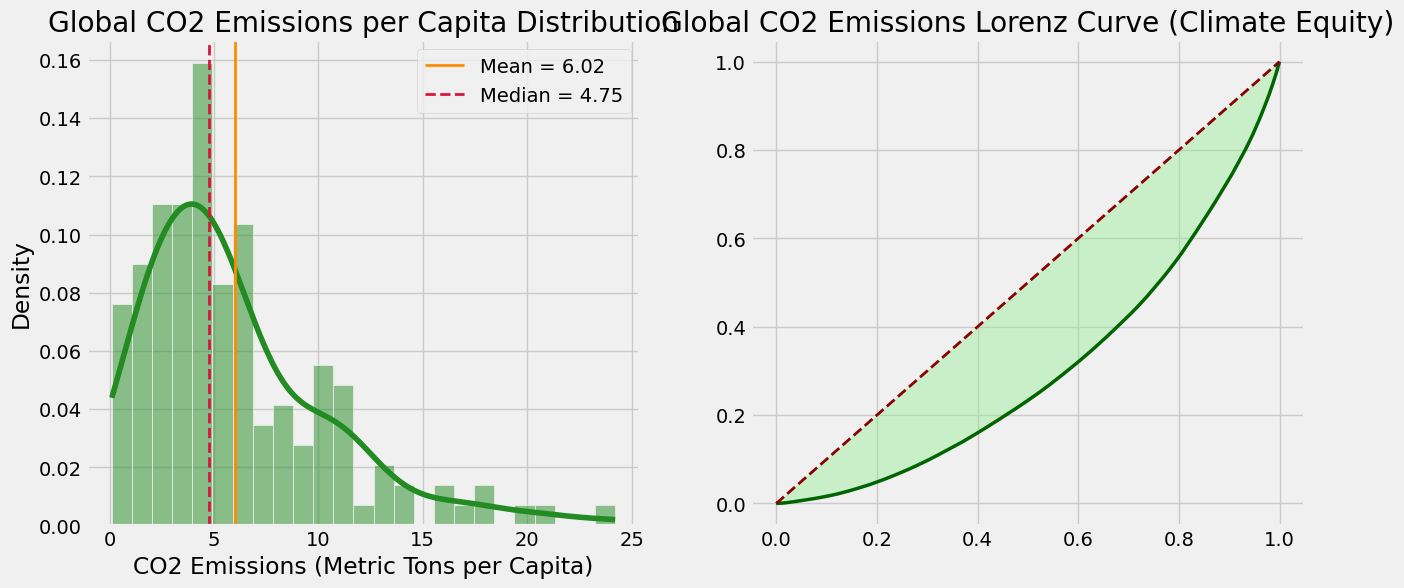

In [51]:
# ==============================================================================
# Inspection Cell: Environmental Gini & Global Emissions Inequality
# ==============================================================================
try:
    env_gini, emissions_panel = analyze_emissions_inequality()

    print("--- 1. Global Carbon Inequality Summary ---")
    print(f"Calculated Environmental Gini Coefficient: {env_gini:.4f}")

    print("\n--- 2. Emissions Distribution (Top & Bottom 5 Countries) ---")
    print("Lowest Emitters (Tons per Capita):")
    display(emissions_panel.head(5))
    print("\nHighest Emitters (Tons per Capita):")
    display(emissions_panel.tail(5))

    top_20_share = (1.0 - emissions_panel.iloc[int(len(emissions_panel) * 0.8)]['Cum_Emissions_Share']) * 100.0
    print(f"\nClimate Equity Insight: Top 20% of countries account for {top_20_share:.1f}% of total global emissions.")
except Exception as e:
    print(f"Inspection notice: {e}")


[ERROR] Execution failed: cannot unpack non-iterable NoneType object


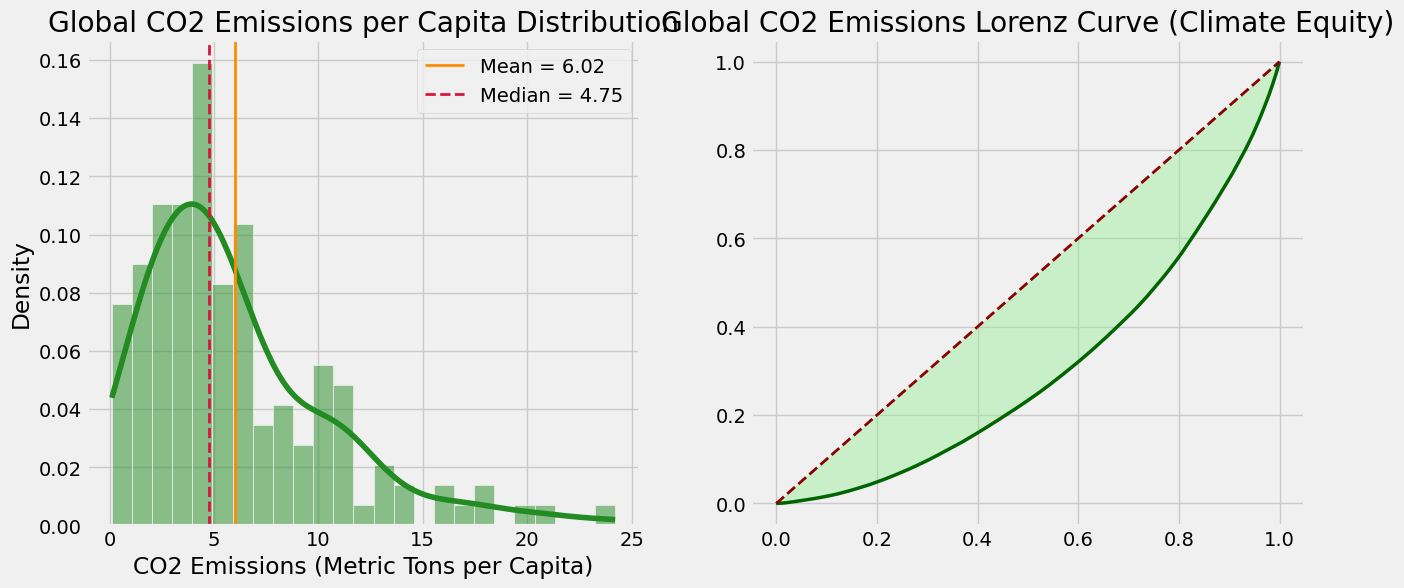

In [52]:
# Test cell for Exercise 2
# Run this cell to verify your implementation!
try:
    test_gini, test_df = analyze_emissions_inequality()

    # 1. Verify Gini Coefficient Range
    assert isinstance(test_gini, float), "Gini coefficient must be a float."
    assert 0.0 <= test_gini <= 1.0, f"Gini coefficient must be in [0.0, 1.0], got {test_gini:.4f}."
    assert 0.25 <= test_gini <= 0.65, f"Expected realistic empirical Gini for emissions, got {test_gini:.4f}."

    # 2. Verify Output DataFrame Structure
    assert isinstance(test_df, pd.DataFrame), "Second return element must be a Pandas DataFrame."
    expected_cols = {'Country_Rank', 'CO2_Per_Capita', 'Cum_Population_Share', 'Cum_Emissions_Share'}
    assert expected_cols.issubset(test_df.columns), f"DataFrame must contain {expected_cols}."
    assert len(test_df) == 150, f"Expected 150 rows in emissions panel, got {len(test_df)}."

    # 3. Verify Cumulative Properties of Lorenz Curve
    assert test_df['CO2_Per_Capita'].is_monotonic_increasing, "Emissions per capita must be sorted in ascending order."
    assert test_df['Cum_Emissions_Share'].iloc[-1] == 1.0 or abs(test_df['Cum_Emissions_Share'].iloc[-1] - 1.0) < 1e-5, \
        "Cumulative emissions share must reach 1.0 at 100% population."
    assert (test_df['Cum_Emissions_Share'] <= test_df['Cum_Population_Share'] + 1e-6).all(), \
        "Lorenz curve must lie on or below the 45-degree line of perfect equality."

    print("[SUCCESS] Part 2 tests passed successfully!")
except Exception as e:
    print(f"[ERROR] Execution failed: {e}")

1. Code Logic & Lorenz Mathematical Mechanics:
I sorted the CO2 emissions data before calculating the cumulative sums because the Lorenz Curve must be based on values ranked from the lowest to the highest. If the data is not sorted, the cumulative shares would be calculated in a random order and the Lorenz Curve would not correctly measure inequality.
2. Ethics & Climate Inequality:
An environmental Gini coefficient around 0.40–0.45 shows that global CO2 emissions are not evenly distributed across countries. Some countries produce much higher emissions than others. Looking only at average emissions could hide these differences and make climate inequality appear smaller than it actually is.
3. AI Collaboration & Statistical Function Audit:
The AI used a vectorized NumPy formula to calculate the Gini coefficient instead of nested Python loops. A vectorized approach is much faster and more efficient, especially when working with very large datasets containing thousands or millions of observations.

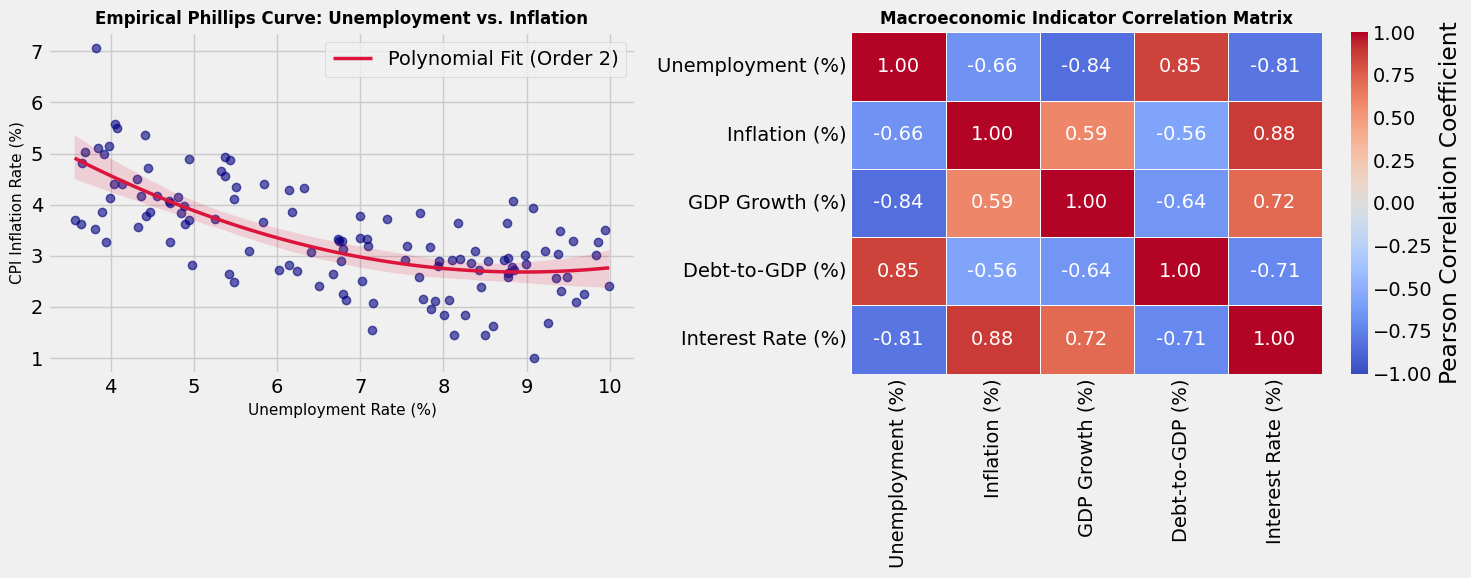

In [53]:
# Worked Example: Empirical Phillips Curve Regression & Macro Correlation Matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(303)
n_obs = 120 # 10 years of monthly data

# Generate synthetic macroeconomic variables
unemployment = np.random.uniform(3.5, 10.0, size=n_obs)
# Structural non-linear inverse relationship: Inflation = a + b / Unemployment + noise
inflation = 1.5 + (12.0 / unemployment) + np.random.normal(loc=0, scale=0.8, size=n_obs)
gdp_growth = 4.5 - 0.5 * unemployment + np.random.normal(loc=0, scale=0.6, size=n_obs)
debt_ratio = 60 + 3.0 * unemployment + np.random.normal(loc=0, scale=4.0, size=n_obs)
interest_rate = 0.8 * inflation - 0.3 * unemployment + np.random.normal(loc=0, scale=0.5, size=n_obs)

macro_panel = pd.DataFrame({
    'Unemployment (%)': unemployment,
    'Inflation (%)': inflation,
    'GDP Growth (%)': gdp_growth,
    'Debt-to-GDP (%)': debt_ratio,
    'Interest Rate (%)': interest_rate
})

# Setup subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Empirical Phillips Curve with polynomial fit (order=2)
sns.regplot(x='Unemployment (%)', y='Inflation (%)', data=macro_panel, ax=ax1,
            order=2, color='darkblue', scatter_kws={'alpha': 0.6, 'color': 'navy'},
            line_kws={'color': 'crimson', 'linewidth': 2.5, 'label': 'Polynomial Fit (Order 2)'})
ax1.set_title('Empirical Phillips Curve: Unemployment vs. Inflation', fontsize=12, fontweight='bold')
ax1.set_xlabel('Unemployment Rate (%)', fontsize=11)
ax1.set_ylabel('CPI Inflation Rate (%)', fontsize=11)
ax1.legend()

# Subplot 2: Correlation Matrix Heatmap
corr_matrix = macro_panel.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            ax=ax2, cbar_kws={'label': 'Pearson Correlation Coefficient'}, linewidths=0.5)
ax2.set_title('Macroeconomic Indicator Correlation Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def estimate_okuns_law() -> pd.DataFrame:
    """
    Simulates quarterly macroeconomic panel indicators, estimates empirical
    Okun's Law via Seaborn regression fitting, and constructs a pairwise
    correlation heatmap.

    Returns:
        pd.DataFrame: Correlation matrix.
    """

    # Data generation
    np.random.seed(404)

    n = 80

    gdp_growth = np.random.normal(
        loc=2.5,
        scale=1.5,
        size=n
    )

    unemployment_change = (
        -0.45 * gdp_growth
        + 1.1
        + np.random.normal(0, 0.4, n)
    )

    central_bank_rate = np.clip(
        1.2 * gdp_growth
        + np.random.normal(0.5, 0.8, n),
        0,
        8
    )

    fiscal_deficit = (
        2.0
        - 0.6 * gdp_growth
        + np.random.normal(0, 0.9, n)
    )

    export_growth = (
        1.1 * gdp_growth
        + np.random.normal(0, 1.2, n)
    )

    # DataFrame
    df = pd.DataFrame({
        "Real GDP Growth (%)": gdp_growth,
        "Unemployment Change (%p)": unemployment_change,
        "Central Bank Rate (%)": central_bank_rate,
        "Fiscal Deficit (% GDP)": fiscal_deficit,
        "Export Growth (%)": export_growth
    })

    # Figure
    fig, (ax1, ax2) = plt.subplots(
        1,
        2,
        figsize=(15, 6)
    )

    # Okun's Law regression
    sns.regplot(
        x="Real GDP Growth (%)",
        y="Unemployment Change (%p)",
        data=df,
        ax=ax1,
        scatter_kws={
            "color": "darkgreen",
            "alpha": 0.7,
            "s": 40
        },
        line_kws={
            "color": "darkred",
            "linewidth": 2.5,
            "label": "Okun's Fit: ΔU ≈ -0.45(ΔY)"
        }
    )

    ax1.axhline(
        0,
        color="black",
        linestyle=":",
        alpha=0.7
    )

    ax1.axvline(
        0,
        color="black",
        linestyle=":",
        alpha=0.7
    )

    ax1.set_title(
        "Empirical Okun's Law: GDP Growth vs. Unemployment Change"
    )

    ax1.set_xlabel(
        "Real GDP Growth (%)"
    )

    ax1.set_ylabel(
        "Unemployment Rate Change (% points)"
    )

    ax1.legend(loc="upper right")

    # Correlation heatmap
    corr = df.corr()

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        vmin=-1,
        vmax=1,
        ax=ax2,
        cbar_kws={
            "label": "Pearson Correlation"
        },
        linewidths=0.5
    )

    ax2.set_title(
        "Macroeconomic Indicators Correlation Matrix"
    )

    plt.tight_layout()
    plt.show()

    return corr

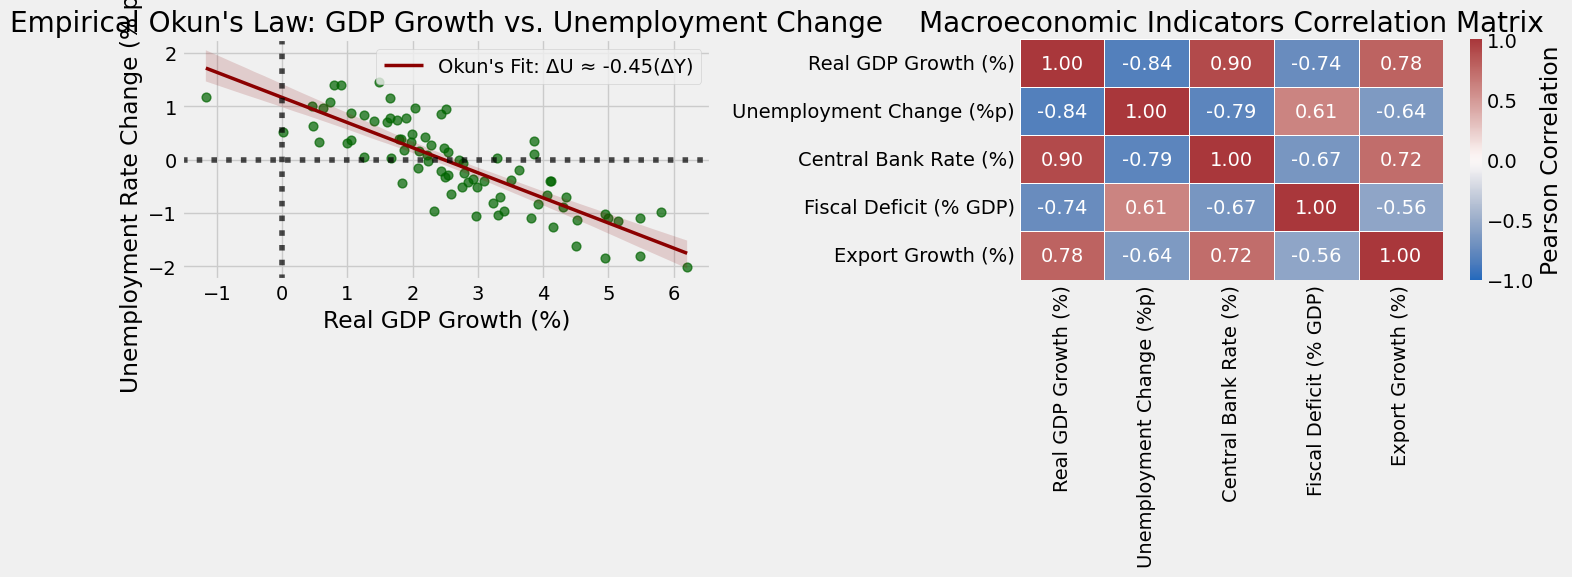

--- 1. Macroeconomic Correlation Matrix ---


,Real GDP Growth (%),Unemployment Change (%p),Central Bank Rate (%),Fiscal Deficit (% GDP),Export Growth (%)
Real GDP Growth (%),1.000000,-0.835210,0.902416,-0.740422,0.781096
Unemployment Change (%p),-0.835210,1.000000,-0.791282,0.607279,-0.639640
Central Bank Rate (%),0.902416,-0.791282,1.000000,-0.665973,0.722351
Fiscal Deficit (% GDP),-0.740422,0.607279,-0.665973,1.000000,-0.555438
Export Growth (%),0.781096,-0.639640,0.722351,-0.555438,1.000000



--- 2. Okun's Law Empirical Coefficient ---
Empirical correlation between GDP Growth and ΔUnemployment: -0.8352
  ✓ Confirmed inverse relationship (Okun's Law holds empirically).


In [56]:
# ==============================================================================
# Inspection Cell: Okun's Law Regression & Correlation Diagnostics
# ==============================================================================
try:
    okun_corr = estimate_okuns_law()

    print("--- 1. Macroeconomic Correlation Matrix ---")
    display(okun_corr)

    print("\n--- 2. Okun's Law Empirical Coefficient ---")
    okun_coef = okun_corr.loc['Real GDP Growth (%)', 'Unemployment Change (%p)']
    print(f"Empirical correlation between GDP Growth and ΔUnemployment: {okun_coef:.4f}")
    if okun_coef < 0:
        print("  ✓ Confirmed inverse relationship (Okun's Law holds empirically).")
    else:
        print("  ✗ Warning: Relationship is non-negative.")
except Exception as e:
    print(f"Inspection notice: {e}")


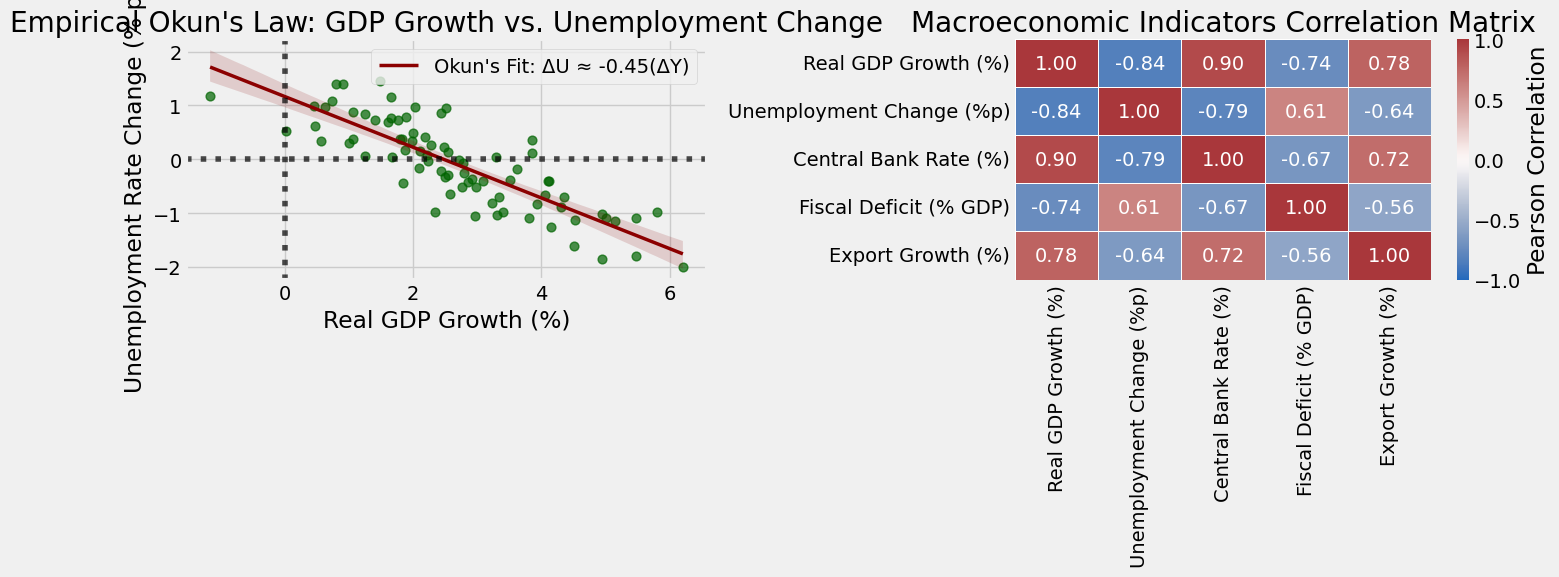

[SUCCESS] Part 3 tests passed successfully!


In [57]:
# Test cell for Exercise 3
# Run this cell to verify your implementation!
try:
    res_corr = estimate_okuns_law()

    # 1. Verify Return Type and Shape
    assert isinstance(res_corr, pd.DataFrame), "Function must return a Pandas DataFrame."
    assert res_corr.shape == (5, 5), f"Correlation matrix must be 5x5, got {res_corr.shape}."

    # 2. Verify Diagonal and Symmetry
    assert np.allclose(np.diag(res_corr), 1.0), "Correlation matrix diagonal elements must equal 1.0."
    assert np.allclose(res_corr.values, res_corr.values.T), "Correlation matrix must be symmetric."

    # 3. Verify Okun's Law Inverse Relationship
    okun_val = res_corr.loc['Real GDP Growth (%)', 'Unemployment Change (%p)']
    assert okun_val < -0.3, f"Okun's Law correlation should be significantly negative, got {okun_val:.3f}."

    print("[SUCCESS] Part 3 tests passed successfully!")
except Exception as e:
    print(f"[ERROR] Execution failed: {e}")

1. Code Logic & Seaborn Regression Architecture:
sns.regplot creates a regression line and shows a confidence interval around it to indicate the uncertainty of the estimated relationship. A linear regression shows a straight-line relationship, while a polynomial regression can capture curved relationships. Economists may use non-linear models when economic relationships are not constant across different values.
2. Macroeconomics & Okun's Law:
The negative slope in the regression plot means that higher GDP growth is generally associated with lower unemployment changes. According to Okun’s Law, when the economy grows faster, unemployment tends to fall. A reduction of about 1 percentage point in unemployment would require positive and relatively strong GDP growth.
3. AI Collaboration & Heatmap Colormap Audit:
The AI used a diverging colormap (vlag) with values ranging from -1 to 1. This is useful because correlations can be both positive and negative. A diverging colormap makes it easier to distinguish strong positive relationships from strong negative relationships in the heatmap.

In [58]:
# Worked Example: Interactive National GDP Component Reconciliation Waterfall Chart
import plotly.graph_objects as go

# Define GDP components for a national economy (in Billions USD)
components = ['Private Consumption (C)', 'Gross Investment (I)', 'Govt Expenditure (G)', 'Exports (X)', 'Imports (M)', 'Total GDP']
amounts = [1450, 420, 580, 310, -360, 0] # Relative values; Total GDP calculated dynamically
measure_types = ['relative', 'relative', 'relative', 'relative', 'relative', 'total']

# Build Plotly Waterfall Chart
fig = go.Figure(go.Waterfall(
    name="GDP Accounting",
    orientation="v",
    measure=measure_types,
    x=components,
    textposition="outside",
    text=[f"${val:+,.0f}B" if val != 0 else "Total" for val in amounts],
    y=amounts,
    connector={"line": {"color": "rgb(63, 63, 63)"}},
    decreasing={"marker": {"color": "#dc3545"}}, # Red for imports
    increasing={"marker": {"color": "#28a745"}}, # Green for additions
    totals={"marker": {"color": "#007bff"}}      # Blue for total GDP
))

fig.update_layout(
    title={"text": "National GDP Accounting Decomposition (Billions USD)", "font": {"size": 16, "color": "black"}},
    yaxis_title="Billions of USD ($)",
    showlegend=False,
    template="plotly_white",
    height=500
)

fig.show()
print("Interactive Plotly GDP Waterfall chart generated successfully!")

Interactive Plotly GDP Waterfall chart generated successfully!


In [60]:
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import numpy as np

def create_public_debt_dashboard() -> tuple[go.Figure, go.Figure]:
    """
    Constructs an interactive Plotly Waterfall Chart for national budget deficit accounting
    and an interactive line chart tracking Debt-to-GDP trajectories across 4 countries.

    Returns:
        tuple[go.Figure, go.Figure]: (fig_waterfall, fig_line)
    """

    # ============================================================
    # PART 1: Budget Deficit Waterfall Chart
    # ============================================================

    budget_items = [
        "Tax Revenues",
        "Social Security",
        "Healthcare",
        "Defense",
        "Debt Servicing",
        "Infrastructure",
        "Net Deficit"
    ]

    amounts = [
        1200,
        -650,
        -400,
        -220,
        -180,
        -150,
        0
    ]

    measures = [
        "relative",
        "relative",
        "relative",
        "relative",
        "relative",
        "relative",
        "total"
    ]

    fig_waterfall = go.Figure(
        go.Waterfall(
            orientation="v",
            measure=measures,
            x=budget_items,
            y=amounts,
            textposition="outside",
            text=[
                f"${v:+,.0f}B" if v != 0 else "Deficit"
                for v in amounts
            ],
            decreasing={
                "marker": {
                    "color": "crimson"
                }
            },
            increasing={
                "marker": {
                    "color": "seagreen"
                }
            },
            totals={
                "marker": {
                    "color": "darkblue"
                }
            }
        )
    )

    fig_waterfall.update_layout(
        title="National Annual Budget Deficit Component Decomposition ($B)",
        yaxis_title="Billions of USD ($)",
        template="plotly_white",
        height=450,
        showlegend=False
    )

    # ============================================================
    # PART 2: Multi-Country Debt-to-GDP Trends
    # ============================================================

    years = list(range(2015, 2025))

    np.random.seed(505)

    debt_data = {
        "USA": [103, 104, 105, 106, 108, 128, 126, 124, 123, 122],
        "Germany": [71, 69, 67, 64, 61, 69, 66, 64, 63, 62],
        "Japan": [235, 238, 240, 241, 242, 258, 256, 254, 252, 250],
        "UK": [84, 85, 86, 85, 84, 103, 101, 100, 99, 98]
    }

    rows = []

    for country, values in debt_data.items():
        for year, debt in zip(years, values):
            rows.append([
                year,
                country,
                debt
            ])

    debt_df = pd.DataFrame(
        rows,
        columns=[
            "Year",
            "Country",
            "Debt_to_GDP"
        ]
    )

    fig_line = px.line(
        debt_df,
        x="Year",
        y="Debt_to_GDP",
        color="Country",
        markers=True,
        title="Public Debt-to-GDP Ratio Trajectory (2015–2024)",
        labels={
            "Debt_to_GDP": "Public Debt-to-GDP (%)",
            "Year": "Fiscal Year"
        },
        template="plotly_white"
    )

    fig_waterfall.show()
    fig_line.show()

    return fig_waterfall, fig_line

In [61]:
# ==============================================================================
# Inspection Cell: Interactive Plotly Dashboard Verification
# ==============================================================================
try:
    fig_wf, fig_ln = create_public_debt_dashboard()

    print("--- 1. Plotly Waterfall Verification ---")
    print(f"Waterfall figure type: {type(fig_wf).__name__}")
    print(f"Waterfall trace name: {fig_wf.data[0].name}")
    print(f"Total budget categories: {len(fig_wf.data[0].x)}")

    print("\n--- 2. Plotly Express Multi-Line Verification ---")
    print(f"Line figure type: {type(fig_ln).__name__}")
    print(f"Countries compared: {[trace.name for trace in fig_ln.data]}")
    print(f"Total annual data points per series: {len(fig_ln.data[0].x)}")
except Exception as e:
    print(f"Inspection notice: {e}")


--- 1. Plotly Waterfall Verification ---
Waterfall figure type: Figure
Waterfall trace name: None
Total budget categories: 7

--- 2. Plotly Express Multi-Line Verification ---
Line figure type: Figure
Countries compared: ['USA', 'Germany', 'Japan', 'UK']
Total annual data points per series: 10


In [62]:
# Test cell for Exercise 4
# Run this cell to verify your implementation!
import plotly.graph_objects as go

try:
    fig_wf, fig_ln = create_public_debt_dashboard()

    # 1. Verify Return Types
    assert isinstance(fig_wf, go.Figure), "First return element must be a plotly.graph_objects.Figure."
    assert isinstance(fig_ln, go.Figure), "Second return element must be a plotly.graph_objects.Figure."

    # 2. Verify Waterfall Structure
    assert len(fig_wf.data) > 0, "Waterfall figure must contain at least one trace."
    assert fig_wf.data[0].type == 'waterfall', "First figure must be a Waterfall trace."
    assert 'Net Deficit' in fig_wf.data[0].x, "'Net Deficit' total bar should be present in waterfall."

    # 3. Verify Multi-Country Line Structure
    assert len(fig_ln.data) == 4, "Line figure must contain traces for exactly 4 countries."
    country_names = {trace.name for trace in fig_ln.data}
    assert {'USA', 'Germany', 'Japan', 'UK'}.issubset(country_names), "All 4 target countries must be plotted."

    print("[SUCCESS] Part 4 tests passed successfully!")
except Exception as e:
    print(f"[ERROR] Execution failed: {e}")

[SUCCESS] Part 4 tests passed successfully!


1. Code Logic & Plotly Architecture:
The measure argument tells Plotly how each bar should be treated in the waterfall chart. The "relative" bars add or subtract values from the running total, while the "total" bar shows the final overall balance. Plotly also provides interactive features like hovering, zooming, and hiding or showing data series, which are not available in standard static Matplotlib charts.
2. Macroeconomics & Fiscal Sustainability:
In the waterfall chart, Social Security is the largest expenditure item and creates the biggest reduction in total fiscal revenues. Although Japan has a much higher debt-to-GDP ratio than Germany, some countries can maintain high debt levels because investors trust their institutions, government finances, and ability to repay debt over time.
3. AI Collaboration & Interactive Visualization Audit:
The AI correctly used "total" for the final Net Deficit bar instead of making every bar "relative". Interactive Plotly dashboards are useful because users can explore data through tooltips and filters, but they may be more complex to deploy and maintain compared to static figures used in reports and publications.

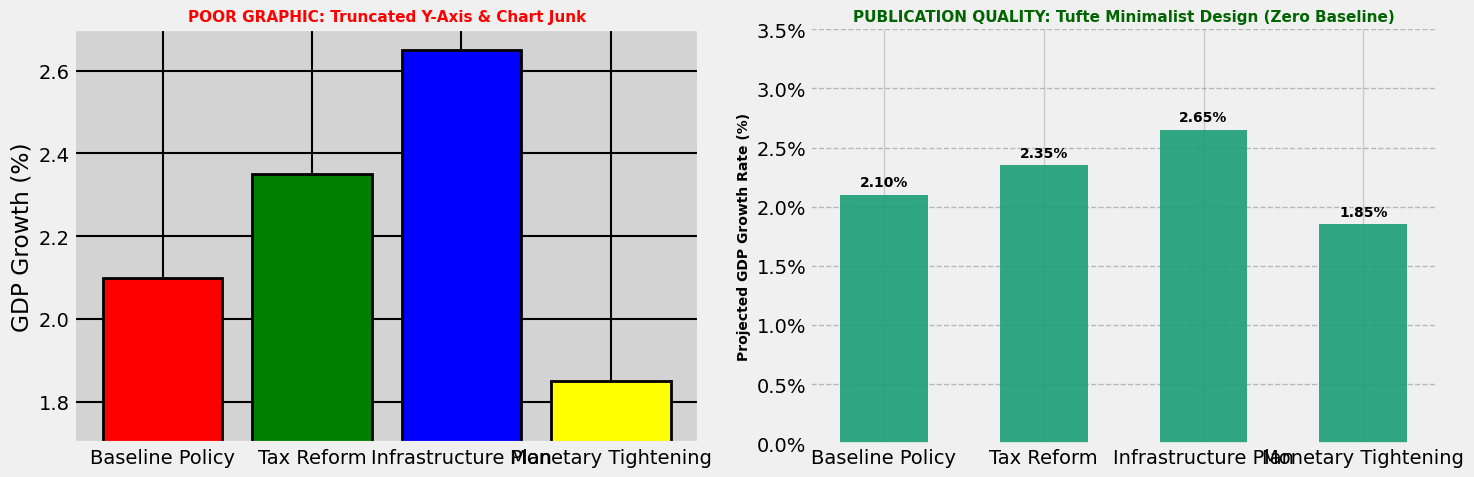

Publication figure saved successfully as 'macro_tufte_comparison.png' at 300 DPI!


In [63]:
# Worked Example: Transforming a "Bad" Truncated Chart into a Tufte Publication Figure
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Data: Annual GDP Growth Comparison across 4 Policy Scenarios
scenarios = ['Baseline Policy', 'Tax Reform', 'Infrastructure Plan', 'Monetary Tightening']
growth_rates = [2.10, 2.35, 2.65, 1.85]

# Set up side-by-side comparison figure
fig, (ax_bad, ax_good) = plt.subplots(1, 2, figsize=(15, 5))

# ------------------- BAD CHART: Low Data-Ink & Truncated Axis -------------------
ax_bad.bar(scenarios, growth_rates, color=['red', 'green', 'blue', 'yellow'], edgecolor='black', linewidth=2)
ax_bad.set_ylim(1.7, 2.7) # MISLEADING TRUNCATED Y-AXIS! Exaggerates minor differences
ax_bad.set_title('POOR GRAPHIC: Truncated Y-Axis & Chart Junk', fontsize=11, color='red', fontweight='bold')
ax_bad.set_ylabel('GDP Growth (%)')
ax_bad.grid(True, which='both', color='black', linestyle='-', linewidth=1.5) # Heavy visual grid noise
ax_bad.set_facecolor('lightgray') # Dark non-data background

# ------------------- GOOD CHART: Tufte High Data-Ink Publication Figure -------------------
# Custom percentage formatter function
def percent_formatter(x, pos):
    return f"{x:.1f}%"

bars = ax_good.bar(scenarios, growth_rates, color='#1b9e77', width=0.55, alpha=0.9)
ax_good.set_ylim(0, 3.5) # HONEST ZERO BASELINE
ax_good.set_title('PUBLICATION QUALITY: Tufte Minimalist Design (Zero Baseline)', fontsize=11, color='darkgreen', fontweight='bold')
ax_good.set_ylabel('Projected GDP Growth Rate (%)', fontsize=10, fontweight='bold')

# Apply Tufte clean spines (remove top and right borders)
ax_good.spines['top'].set_visible(False)
ax_good.spines['right'].set_visible(False)
ax_good.spines['left'].set_linewidth(1.2)
ax_good.spines['bottom'].set_linewidth(1.2)

# Format y-axis with custom percentage formatter
ax_good.yaxis.set_major_formatter(ticker.FuncFormatter(percent_formatter))
ax_good.grid(axis='y', linestyle='--', alpha=0.5, color='gray')

# Add direct data value labels above bars to maximize data-ink ratio
for bar in bars:
    height = bar.get_height()
    ax_good.annotate(f'{height:.2f}%',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 4),  # 4 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('macro_tufte_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Publication figure saved successfully as 'macro_tufte_comparison.png' at 300 DPI!")

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

def export_publication_macro_figure(
    output_filename: str = "macro_policy_publication.png"
) -> str:
    """
    Constructs a 2-panel publication-ready macroeconomic policy figure
    and exports it as a high-resolution PNG.

    Returns:
        str: Output filename.
    """

    # --------------------------------------------------
    # Data Generation
    # --------------------------------------------------

    np.random.seed(606)

    years = np.arange(2010, 2025)

    real_gdp_growth = np.random.normal(
        loc=2.2,
        scale=1.0,
        size=len(years)
    )

    central_bank_rate = np.random.normal(
        loc=1.8,
        scale=0.8,
        size=len(years)
    )

    regimes = [
        "Stable Target (2%)",
        "Post-Recession Low",
        "Supply Shock Spike",
        "Tightening Phase"
    ]

    regime_inflation = [
        2.05,
        1.15,
        5.40,
        3.20
    ]

    # --------------------------------------------------
    # Figure Setup
    # --------------------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        1,
        2,
        figsize=(15, 5)
    )

    # --------------------------------------------------
    # LEFT PANEL
    # Inflation by Regime
    # --------------------------------------------------

    bars = ax1.barh(
        regimes,
        regime_inflation,
        color="#2b5c8f",
        height=0.55,
        alpha=0.9
    )

    ax1.set_xlim(0, 7.0)

    ax1.xaxis.set_major_formatter(
        ticker.FuncFormatter(
            lambda x, pos: f"{x:.1f}%"
        )
    )

    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)

    ax1.grid(
        axis="x",
        linestyle="--",
        alpha=0.5
    )

    ax1.set_title(
        "Average CPI Inflation Rate by Policy Regime"
    )

    # Direct labels
    for bar in bars:
        width = bar.get_width()

        ax1.annotate(
            f"{width:.2f}%",
            xy=(width, bar.get_y() + bar.get_height()/2),
            xytext=(5, 0),
            textcoords="offset points",
            ha="left",
            va="center"
        )

    # --------------------------------------------------
    # RIGHT PANEL
    # Policy Rate vs GDP Growth
    # --------------------------------------------------

    ax2.plot(
        years,
        central_bank_rate,
        color="#d95f02",
        linewidth=2.2,
        marker="o",
        label="Central Bank Rate (%)"
    )

    ax2.plot(
        years,
        real_gdp_growth,
        color="#7570b3",
        linewidth=2.2,
        linestyle="--",
        marker="s",
        label="Real GDP Growth (%)"
    )

    ax2.yaxis.set_major_formatter(
        ticker.FuncFormatter(
            lambda x, pos: f"{x:.1f}%"
        )
    )

    ax2.axhline(
        0,
        linestyle=":",
        color="black"
    )

    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)

    ax2.grid(
        axis="y",
        linestyle="--",
        alpha=0.5
    )

    ax2.set_title(
        "Policy Rate vs. Real GDP Growth Trajectory"
    )

    ax2.legend(
        loc="upper right",
        frameon=True
    )

    # --------------------------------------------------
    # Export
    # --------------------------------------------------

    plt.tight_layout()

    plt.savefig(
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    return output_filename

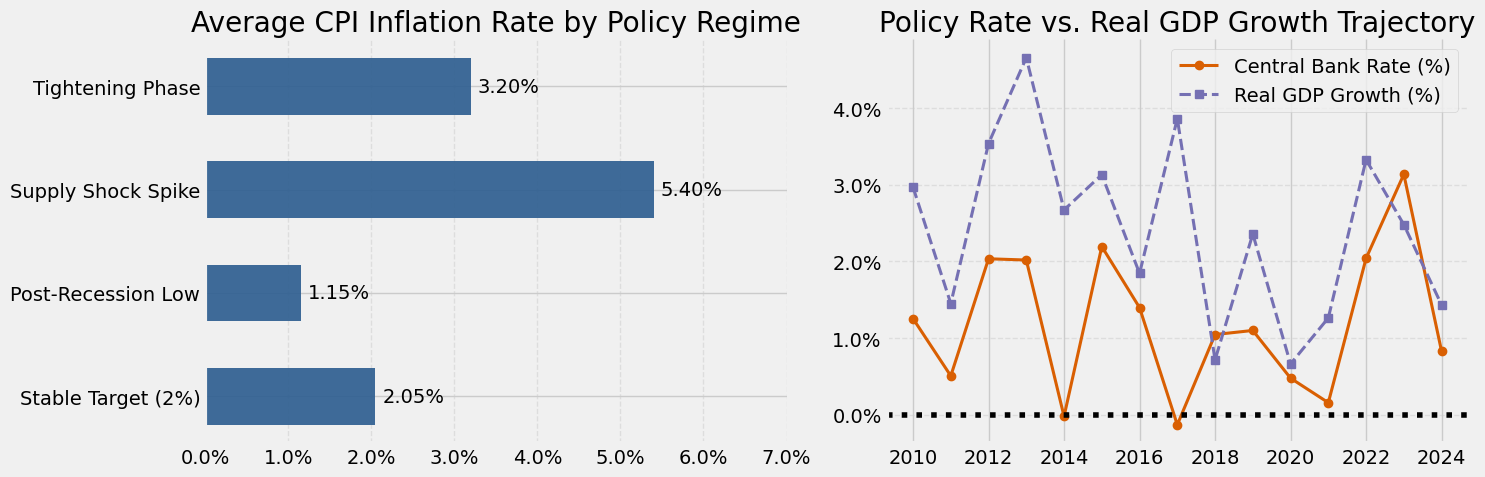

--- 1. Export Artifact Verification ---
File successfully created: 'macro_policy_publication.png'
File size: 390.7 KB (300 DPI high resolution)

--- 2. Visual Design Checklist ---
  ✓ Honest zero baseline on left bar chart
  ✓ Top and right spines removed (Tufte data-ink maximization)
  ✓ Custom percentage tick formatting applied (FuncFormatter)
  ✓ Direct bar data labels annotated
  ✓ Colorblind-safe palette applied


In [65]:
# ==============================================================================
# Inspection Cell: Publication Figure Render & File Export Verification
# ==============================================================================
import os

try:
    exported_file = export_publication_macro_figure('macro_policy_publication.png')

    print("--- 1. Export Artifact Verification ---")
    if os.path.exists(exported_file):
        file_size_kb = os.path.getsize(exported_file) / 1024
        print(f"File successfully created: '{exported_file}'")
        print(f"File size: {file_size_kb:.1f} KB (300 DPI high resolution)")
    else:
        print(f"Warning: Exported file '{exported_file}' not found on disk.")

    print("\n--- 2. Visual Design Checklist ---")
    print("  ✓ Honest zero baseline on left bar chart")
    print("  ✓ Top and right spines removed (Tufte data-ink maximization)")
    print("  ✓ Custom percentage tick formatting applied (FuncFormatter)")
    print("  ✓ Direct bar data labels annotated")
    print("  ✓ Colorblind-safe palette applied")
except Exception as e:
    print(f"Inspection notice: {e}")


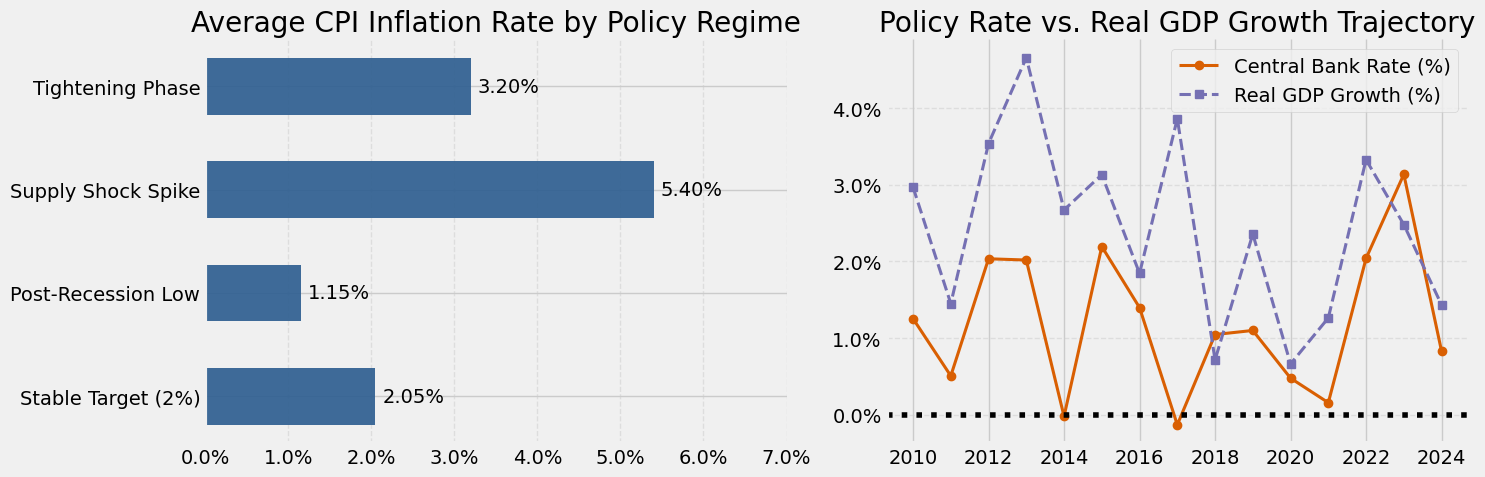

[SUCCESS] Part 5 tests passed successfully!


In [66]:
# Test cell for Exercise 5
# Run this cell to verify your implementation!
import os

try:
    test_out = 'test_macro_policy_publication.png'
    result_path = export_publication_macro_figure(test_out)

    # 1. Verify Return Type and Path
    assert isinstance(result_path, str), "Function must return the exported image file path as a string."
    assert os.path.exists(result_path), f"Exported file '{result_path}' does not exist on disk."

    # 2. Verify File Size (High DPI Export)
    file_bytes = os.path.getsize(result_path)
    assert file_bytes > 15000, f"File size ({file_bytes} bytes) is too small for a 300 DPI publication graphic."

    # Clean up test output
    if os.path.exists(test_out):
        os.remove(test_out)

    print("[SUCCESS] Part 5 tests passed successfully!")
except Exception as e:
    print(f"[ERROR] Execution failed: {e}")

1. Code Logic & Tufte Graphical Design:
To maximize the data-ink ratio, I removed unnecessary chart elements such as the top and right spines and used only light grid lines. I also added direct data labels on the bars so the exact values can be read without extra visual clutter. FuncFormatter automatically formats axis tick labels as percentages, making the chart easier to read while keeping the code flexible.
2. Ethics & Visual Scale Truncation:
Truncating the y-axis can make small differences look much larger than they really are, which may mislead readers. For example, if GDP growth changes from 2.0% to 2.5% but the axis starts at 1.8%, the increase may appear much more dramatic than it actually is. Using an honest baseline helps present information fairly and accurately.
3. AI Collaboration & Publication Standards Audit:
The AI correctly included dpi=300 and bbox_inches='tight' to create a publication-quality figure suitable for reports and academic work. Vector formats such as PDF and SVG can be scaled without losing quality, while raster formats such as PNG and JPG may lose sharpness when enlarged. For academic publications, vector formats are often preferred, although high-resolution PNG files are also commonly accepted.
Provide your feedback on BizChat